In [15]:
import os
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
import nltk
import pandas as pd
from pypdf import PdfReader
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline


# Comando mágico para renderizar gráficos dentro del Notebook
%matplotlib inline
sns.set_theme(style="whitegrid")

# Preparar stopwords
try:
    nltk.data.find("corpora/stopwords")
except LookupError:
    nltk.download("stopwords")

stopwords_espanol = stopwords.words("spanish")

Librerías y Manejo de Idiomas (Stopwords con NLTK)
Importación de Librerías y Configuración del Idioma

En esta sección se cargan las librerías necesarias para el análisis de texto y aprendizaje automático.

Un punto clave es el uso de NLTK para descargar las palabras vacías (stopwords) en español. Las stopwords son palabras muy comunes (como "de", "la", "que", "en") que no aportan información sobre el tema del documento y deben filtrarse.

Observación sobre el idioma:

El filtro actual está configurado exclusivamente para español. Si se intenta clasificar un PDF redactado en inglés o en otro idioma, las palabras comunes de ese idioma (como "the", "and", "is") no serán eliminadas. Esto provocará que el modelo considere esas palabras dentro del vocabulario, afectando la precisión de la clasificación. Para dar soporte multiidioma, se requeriría un detector automático de idioma antes de aplicar el filtro. Sin embargo eso no afecto si el algoritmo puede leer documentos en un idioma u otro.

In [16]:
def extraer_texto_pdf(ruta_pdf: str) -> str:
    texto = ""
    try:
        reader = PdfReader(ruta_pdf)
        for pagina in reader.pages:
            contenido = pagina.extract_text()
            if contenido:
                texto += contenido + " "
    except Exception as e:
        print(f"Error al leer {ruta_pdf}: {e}")
    return texto.strip()


def cargar_dataset_entrenamiento(carpeta_raiz: str):
    textos, categorias = [], []
    for categoria in os.listdir(carpeta_raiz):
        ruta_categoria = os.path.join(carpeta_raiz, categoria)
        if os.path.isdir(ruta_categoria):
            for archivo in os.listdir(ruta_categoria):
                if archivo.lower().endswith(".pdf"):
                    ruta_pdf = os.path.join(ruta_categoria, archivo)
                    texto_extraido = extraer_texto_pdf(ruta_pdf)
                    if texto_extraido:
                        textos.append(texto_extraido)
                        categorias.append(categoria)
    return textos, categorias

Extracción de Texto de los PDF (extraer_texto_pdf)
Función de Extracción de Texto

Esta función abre un archivo PDF individual y recupera su contenido de texto página por página.

Funcionamiento: Utiliza la librería pypdf para recorrer el archivo y concatenar todo el texto legible en una sola cadena de caracteres. Incluye un control de errores (try-except) para evitar que la ejecución se detenga si un archivo está dañado.

Limitación importante: pypdf solo extrae texto digital que se pueda seleccionar. Si un documento es una imagen escaneada o una foto de un papel, devolverá una cadena vacía. En esos casos, se requeriría una herramienta de reconocimiento óptico de caracteres (OCR) como Tesseract.

In [17]:
def graficar_agrupacion_vectores(modelo, X_train, y_train):
    # Transformar texto a vectores TF-IDF
    vectorizador = modelo.named_steps["tfidfvectorizer"]
    X_tfidf = vectorizador.transform(X_train)

    # Reducir las dimensiones a un plano 2D (X, Y)
    svd = TruncatedSVD(n_components=2, random_state=42)
    vectores_2d = svd.fit_transform(X_tfidf)

    # Crear la gráfica
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        x=vectores_2d[:, 0],
        y=vectores_2d[:, 1],
        hue=y_train,
        style=y_train,
        s=140,
        palette="tab10",
    )

    plt.title(
        "Agrupación de Documentos PDF en el Espacio Vectorial (TF-IDF)",
        fontsize=13,
        weight="bold",
    )
    plt.xlabel("Dimensión Principal 1")
    plt.ylabel("Dimensión Principal 2")
    plt.legend(title="Categoría", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

Carga del Dataset (cargar_dataset_entrenamiento)
Carga Automática de Datos y Etiquetado

Esta función automatiza la lectura de la estructura de carpetas sin necesidad de definir categorías manualmente en el código.

Funcionamiento: Escanea la carpeta raíz Datos_Entrenamiento y detecta cada subcarpeta existente. El nombre de cada subcarpeta se asigna automáticamente como la categoría (por ejemplo: Deportes, Finanzas, Tecnología). Luego, lee todos los PDFs dentro de cada carpeta y almacena tanto el texto extraído como su respectiva etiqueta.

Ventaja: Permite agregar o renombrar categorías simplemente creando o modificando las carpetas en el sistema de archivos, sin alterar una sola línea de código.

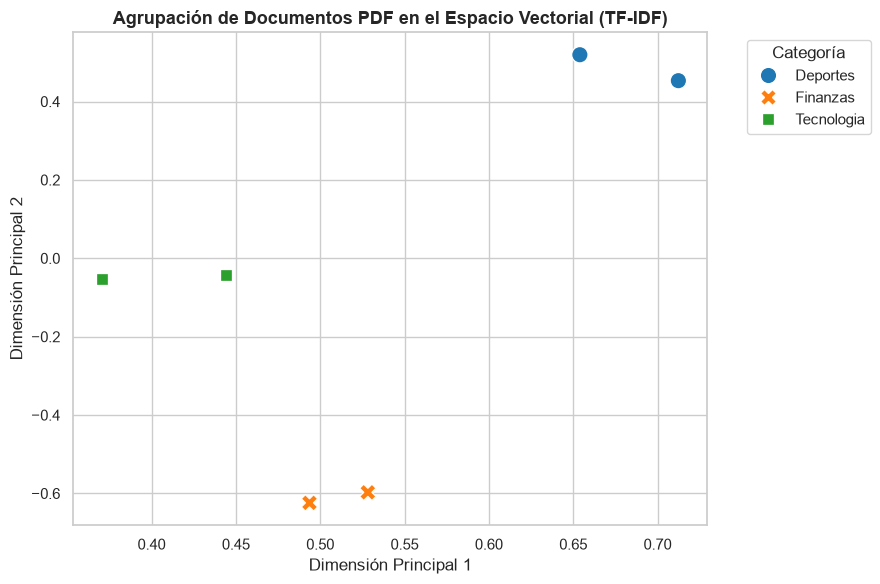

In [18]:
carpeta_entrenamiento = "Datos_Entrenamiento"
X_train, y_train = cargar_dataset_entrenamiento(carpeta_entrenamiento)

# Definir y entrenar pipeline
modelo = make_pipeline(
    TfidfVectorizer(stop_words=stopwords_espanol, lowercase=True),
    MultinomialNB(),
)

modelo.fit(X_train, y_train)

# Generar y mostrar el gráfico en el Notebook
graficar_agrupacion_vectores(modelo, X_train, y_train)

Análisis Crítico de la Visualización y Limitaciones del Modelo

A pesar de que la gráfica separa los grupos claramente en el plano 2D, existen dos limitaciones principales en esta versión inicial:

Escasez de Datos y Vocabulario Pobre:
Al entrenar únicamente con 2 archivos PDF por categoría, el vocabulario que extrae el vectorizador es muy acotado. Si ingresamos un archivo PDF nuevo con palabras diferentes o sinónimos que no venían en esos 2 documentos iniciales, el modelo no tendrá suficiente información para compararlo y asignará probabilidades poco confiables.

Categorías Demasiado Generales (Problema de Granularidad):
Una categoría como "Deportes" es un término muy amplio que abarca muchas disciplinas distintas (fútbol, natación, automovilismo, tenis, etc.). Si el modelo solo aprendió con documentos de fútbol, al escanear un texto nuevo sobre otro deporte (por ejemplo, fórmula 1 o tenis), podría no encontrar coincidencias y clasificarlo por error en "Finanzas" o "Tecnología".

In [19]:
carpeta_pruebas = "Datos_Pruebas"
resultados = []

if os.path.exists(carpeta_pruebas):
    archivos_prueba = [
        f for f in os.listdir(carpeta_pruebas) if f.lower().endswith(".pdf")
    ]

    for archivo in archivos_prueba:
        ruta_pdf = os.path.join(carpeta_pruebas, archivo)
        texto = extraer_texto_pdf(ruta_pdf)

        if texto:
            categoria_predicha = modelo.predict([texto])[0]
            probabilidades = modelo.predict_proba([texto])[0]
            confianza = max(probabilidades) * 100

            resultados.append({
                "Archivo PDF": archivo,
                "Categoría Asignada": categoria_predicha,
                "Confianza (%)": f"{round(confianza, 2)}%",
            })
        else:
            resultados.append({
                "Archivo PDF": archivo,
                "Categoría Asignada": "No legible / Vacío",
                "Confianza (%)": "0.0%",
            })

# Crear DataFrame y visualizarlo con formato HTML en Jupyter
df_resultados = pd.DataFrame(resultados)
df_resultados

,Archivo PDF,Categoría Asignada,Confianza (%)
0,Avances Tecnologicos y Modernos.pdf,Tecnologia,37.03%
1,El futuro del Deporte para las gente.pdf,Deportes,42.8%
2,Finanzas Basicas.pdf,Finanzas,53.78%


 Clasificación de Documentos Nuevos y Cálculo de Confianza
Evaluación de Documentos de Prueba

Esta sección procesa los archivos no vistos ubicados en la carpeta Datos_Pruebas.

Predicción y Confianza: Para cada archivo, el modelo determina la categoría más probable (predict) y extrae el porcentaje de certidumbre o confianza matemática de esa decisión (predict_proba).

Manejo de archivos sin texto: Si un PDF es una imagen o está vacío, el sistema lo identifica y le asigna la etiqueta "No legible / Vacío" con un 0% de confianza, evitando predicciones erróneas.

Conclusión y Soluciones para el Futuro

Ampliación del Dataset: Alimentar la carpeta de entrenamiento con más variedad de documentos (mínimo entre 15 y 30 PDFs por categoría) para enriquecer el vocabulario del modelo.

Jerarquización de Categorías: Subdividir temas muy amplios. Por ejemplo, en lugar de usar solo "Deportes", estructurar subcarpetas como Deportes/Futbol, Deportes/Motor o Deportes/Tenis.